In [52]:
from scipy.spatial import Delaunay
import os
import argparse
from glob import glob

import numpy as np
import pandas as pd
from PIL import Image
from tifffile import imread

from matplotlib import pyplot as plt

from matplotlib.lines import Line2D

color_palette = [
    "#FF2BD6",  # magenta
    "#FF7A00",  # orange
    "#39FF14",  # neon green
    "#00E5FF",  # cyan
    "#B388FF",  # lavender
    "#FFE600",  # yellow
    "#2F6BFF",  # blue
    "#FF3D3D",  # red
]

In [53]:
pick_well = "A1"
pick_site = "1"
base_dir = "C:/Users/shery/Documents/bioinfo_windows/ARCOS-geminin-unibe2026/data"

DIR_OUT_DATA = "output-data"
DIR_OUT_PLOT = "output-plots"

SAMPLE_OUT_DIR = f"{DIR_OUT_DATA}/well_{pick_well}_site_{pick_site}"
DIR_OUT_PLOT = f"{DIR_OUT_PLOT}/well_{pick_well}_site_{pick_site}"
os.makedirs(DIR_OUT_PLOT, exist_ok=True)

os.chdir("C:/Users/shery/Documents/bioinfo_windows/ARCOS-geminin-unibe2026/")

In [54]:
try:
    # Load raw images
    np_erk = imread(glob(os.path.join(base_dir, f"Well{pick_well}_Seq*_Site{pick_site}_C3*.tif"))[0])

    # Load saved results
    np_lab_filt = np.load(f"{SAMPLE_OUT_DIR}/np_lab_large.npz")["arr"]
    np_lab_ring = np.load(f"{SAMPLE_OUT_DIR}/np_lab_ring.npz")["arr"]

    df_tracks = pd.read_csv(f"{SAMPLE_OUT_DIR}/df_tracks.csv.gz", compression="gzip")
    df_arcos_data = pd.read_csv(f"{SAMPLE_OUT_DIR}/df_arcos_data.csv.gz", compression="gzip")
    df_ce = pd.read_csv(f"{SAMPLE_OUT_DIR}/df_ce.csv.gz", compression="gzip")
    df_ce_filt = pd.read_csv(f"{SAMPLE_OUT_DIR}/df_ce_filt.csv.gz", compression="gzip")
    df_ce_stats = pd.read_csv(f"{SAMPLE_OUT_DIR}/df_ce_stats.csv.gz", compression="gzip")
    df_ce_points = pd.read_csv(f"{SAMPLE_OUT_DIR}/ce_points.csv")

    print(f"Successfully loaded image stacks and outputs for {SAMPLE_OUT_DIR}!")
except Exception as e:
    print(f"Failed to load: {e}")

Successfully loaded image stacks and outputs for output-data/well_A1_site_1!


In [55]:
np_lab_ring_meas = np.load(f"{SAMPLE_OUT_DIR}/np_lab_ring_meas.npz")["arr"]
# umm i just want to invert the erk
np_erk = np_erk.max() + np_erk.min() - np_erk

# merge cl_id into df_arcos_data on t and track_id
df_arcos_data = df_arcos_data.merge(df_ce_filt[['t', 'track_id', 'cl_id']],
                                    on=['t', 'track_id'], how='left', validate='m:1')

In [56]:
# this is the all-purpose version of df_arcos_data which includes cl_id
display(df_arcos_data)

,t,obj_id,x,y,intensity_mean_nuc,intensity_mean_cyto,track_id,cnr,rt,cnr.resc,cnr.bin,cl_id
0,0,124,922.547746,696.155080,5434.708174,4843.657609,2,0.891245,0.000000,0.000000,0,NaN
1,1,64,918.625977,705.525391,3961.966797,2857.135897,2,0.721141,0.083333,0.000000,0,NaN
2,2,127,922.197446,704.499018,3823.117878,2737.850282,2,0.716130,0.166667,0.000000,0,NaN
3,3,130,924.901587,704.820106,3903.353439,2782.088050,2,0.712743,0.250000,0.000000,0,NaN
4,4,83,924.850669,701.572606,3867.683831,2801.118033,2,0.724237,0.333333,0.000000,0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
207053,523,302,38.429612,794.458738,6933.541262,6560.403279,3859,0.946184,43.583333,0.007467,0,NaN
207054,524,310,38.104326,794.646310,6973.083969,6630.907591,3859,0.950929,43.666667,0.001840,0,NaN
207055,525,264,36.144703,795.948320,6908.767442,6461.254717,3859,0.935225,43.750000,0.000000,0,NaN
207056,526,263,36.402667,796.477333,6908.650667,6415.925806,3859,0.928680,43.833333,0.000000,0,NaN


### Some functions for plotting the scipy Delaunay

In [57]:
def plot_cell_ids(points, tri, image=None, xlim=None, ylim=None, figsize=(10, 10), labels=None):
    """Draw the mesh and write a label next to every cell, to help you choose cells by number.

    points : (n, 2) array of x, y coordinates; row i is vertex i
    tri    : the Delaunay object built from exactly these points
    image  : optional background image
    xlim, ylim : zoom window. Only cells inside it are labelled. Give ylim largest value first
                 (e.g. (700, 450)) because imshow puts y = 0 at the top.
    labels : the column itself, one entry per point, e.g. labels=arcos_frame["track_id"].
             Default None prints the vertex ids (row positions within this frame).
    """
    # --- check the inputs agree with each other before drawing anything ---
    assert len(points) == tri.npoints, f"{len(points)} points but triangulation has {tri.npoints}"
    if isinstance(labels, str):
        raise TypeError("pass the column itself, e.g. labels=arcos_frame['track_id'], not its name")
    # np.asarray -> plain array, so lab[v] is by position and not by a (possibly different) pandas index;
    # we keep `labels` itself because the title reads its .name
    lab = None if labels is None else np.asarray(labels)
    if lab is not None:
        assert len(lab) == len(points), "labels must have one entry per point"

    # --- background, mesh and cell dots ---
    fig, ax = plt.subplots(figsize=figsize)
    if image is not None:
        ax.imshow(image, cmap="Greys", interpolation="none", vmin=image.min(), vmax=image.max())
    ax.triplot(points[:, 0], points[:, 1], tri.simplices, alpha=0.3, linewidth=0.5, color="yellow")
    ax.plot(points[:, 0], points[:, 1], 'o', markersize=3)

    # --- zoom, and work tri_df which cells fall inside the window (only those get text) ---
    inside = np.ones(len(points), bool)         # start with every cell labelled
    if xlim:
        inside &= (points[:, 0] >= min(xlim)) & (points[:, 0] <= max(xlim))
        ax.set_xlim(xlim)
    if ylim:
        inside &= (points[:, 1] >= min(ylim)) & (points[:, 1] <= max(ylim))
        ax.set_ylim(ylim)                       # keep the order given, so the reversed y stays reversed

    # --- write one label per visible cell, nudged up and right so it doesn't sit on the dot ---
    for v in np.where(inside)[0]:
        txt = str(lab[v]) if lab is not None else str(v)
        ax.annotate(txt, points[v], fontsize=7, xytext=(3, 3), textcoords="offset points", color="lightgrey")

    # title: the Series name if one was passed (e.g. "track_id"), otherwise a generic description
    ax.set_title(getattr(labels, "name", None) or ("Vertex IDs" if labels is None else "Custom labels"))

    return fig, ax


def plot_layers(points, tri, tri_layers_df, image=None, show_mesh=True, labels="track_id",
                xlim=None, ylim=None, figsize=(8, 8), title=None, ax=None, legend=True, vmin=None, vmax=None, cmap=color_palette, size=30, legend_max=4):
    """Draw all cells in grey and the selected cells coloured by layer (layer 0 = picked, outlined).

    points     : (n, 2) array of x, y coordinates; row i is vertex i
    tri        : the Delaunay object built from exactly these points
    tri_layers_df : table of the selected cells with columns vertex, layer
    labels     : name of a tri_layers_df column to print next to each selected cell
                 ("track_id", "vertex", ...), or None for no text.
    ax         : draw into this existing axes (used for montages); if None a new figure is made
    legend     : show the layer colour legend
    """

    # --- figure: new one, or the axes we were given ---
    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    else:
        fig = ax.figure

    # --- background, mesh, and every cell as a light grey dot ---
    if image is not None:
        ax.imshow(image, cmap="Greys", interpolation="none",
                  vmin=image.min() if vmin is None else vmin,
                  vmax=image.max() if vmax is None else vmax)
    if show_mesh:
        ax.triplot(points[:, 0], points[:, 1], tri.simplices, alpha=0.3, linewidth=0.5, color="yellow")
    ax.plot(points[:, 0], points[:, 1], 'o', markersize=size**0.5/2, color="lightgrey", zorder=2)

    # --- legend, zoom, title ---
    # colormap...
    palette = lambda l: cmap[l % len(cmap)]
    handles = [Line2D([], [], marker="o", ls="", color=palette(l),
                      label="core cells" if l == 0 else f"{l}-step") for l in range(legend_max+1)]
    if legend:
        ax.legend(handles=handles, loc="upper right")
    if xlim: ax.set_xlim(xlim)
    if ylim: ax.set_ylim(ylim)
    ax.set_title(title or f"Selection expanded by Delaunay layer(s)")

    # break, only plot mesh if tri_layers_df is empty
    if tri_layers_df is None:
        print('layers df is empty')
        return fig, ax

    # --- check inputs ---
    assert len(points) == tri.npoints, f"{len(points)} points but triangulation has {tri.npoints}"
    selected = tri_layers_df.drop_duplicates("vertex_id")          # one row per selected cell

    # build vertex index: layer and cl_id
    layer_of = selected.set_index("vertex_id")["layer"] if "layer" in selected.columns else None
    cl_of = selected.set_index("vertex_id")["cl_id"] if "cl_id" in selected.columns else None
    n_layers = int(layer_of.max()) if len(layer_of) else 0

    # --- selected cells, drawn layer by layer in that layer's colour ---
    # zorder makes inner layers sit on top of outer ones

    for l in range(n_layers + 1):
        ids = layer_of.index[layer_of == l].to_numpy()      # vertex ids in this layer
        if len(ids) == 0:
            continue

        no_ce = np.zeros(len(ids), dtype=bool)               # default: no highlighted cells
        if cl_of is not None:
            no_ce = (cl_of.reindex(ids) == -1).to_numpy(dtype=bool)   # cl_id == -1

        z = 3 + (n_layers - l)
        ax.scatter(points[ids[no_ce], 0], points[ids[no_ce], 1], s=size,
                facecolors='none', edgecolors="#FF2BD6", linewidths=1.5, zorder=z)   # pink circle
        ax.scatter(points[ids[~no_ce], 0], points[ids[~no_ce], 1], s=size,
                color=palette(l), zorder=z)                                          # the rest

    # --- text next to each selected cell: the chosen column's value, placed at that cell's coordinates ---
    if labels is not None:
        for v, text in zip(selected["vertex_id"], selected[labels]):
            ax.annotate(str(text), points[v], fontsize=7, xytext=(3, 3),
                        textcoords="offset points", zorder=10, color="lightgrey")

    return fig, ax

# Initialize Delaunay objects

In [58]:
n_frame_show = 25

np_erk_show = np_erk[n_frame_show]

np_arcos_coords = df_arcos_data[df_arcos_data['t'] == n_frame_show][['x','y']].values
tri_points = np_arcos_coords

# Compute Delaunay triangulation
tri = Delaunay(tri_points)

# Compute Delaunay neighbor vertices
indptr, indices = tri.vertex_neighbor_vertices

Look at the track IDs

['t', 'obj_id', 'x', 'y', 'intensity_mean_nuc', 'intensity_mean_cyto', 'track_id', 'cnr', 'rt', 'cnr.resc', 'cnr.bin', 'cl_id']


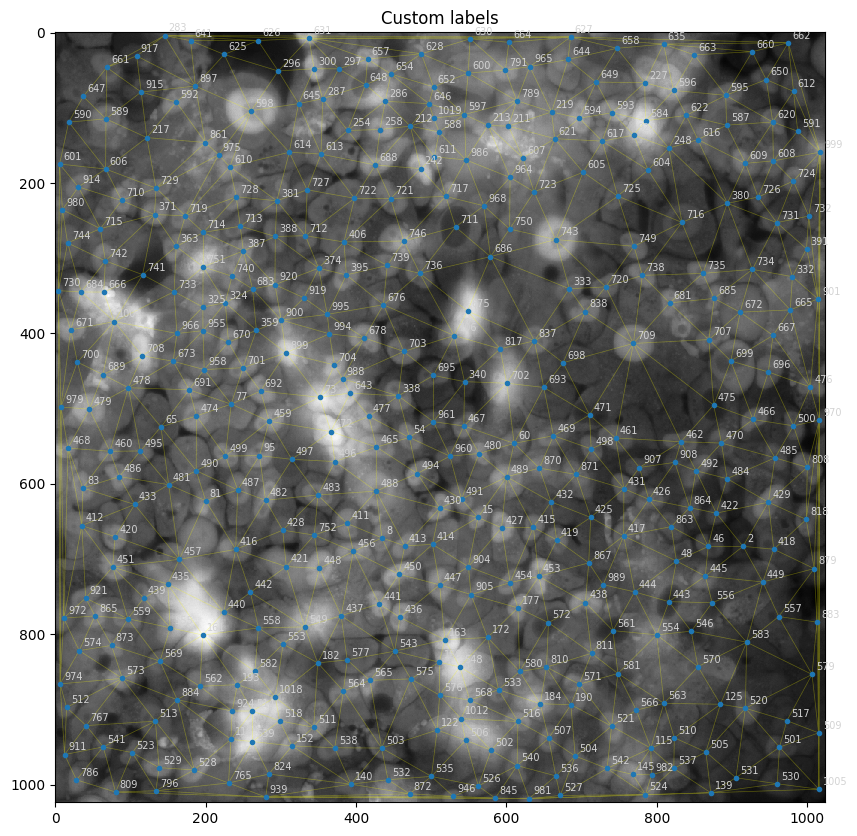

In [59]:
# Plot
tri_frame = df_arcos_data[df_arcos_data['t'] == n_frame_show].reset_index(drop=True)   # row i == vertex i
assert len(tri_frame) == len(tri_points)

tri_id_col = "track_id"   # e.g. "track_id" / "trackID" -- whatever identifies a cell in df_arcos_data
print(tri_frame.columns.tolist())

# look at the IDs
plot_cell_ids(tri_points, tri, image=np_erk_show,
              labels=tri_frame[tri_id_col].to_numpy())
plt.show()

In [60]:
# Pick your track IDs, then convert to vertex IDs
picked_track = [570, 563]

picked_v = tri_frame.index[tri_frame['track_id'].isin(picked_track)].tolist()
print(f"picked track IDs: {picked_track}")
print(f"these correspond to vertex IDs: {picked_v}")

picked track IDs: [570, 563]
these correspond to vertex IDs: [191, 197]


# Building Delaunay neighbors

## Scipy djikstra
- Uses a CSR matrix (compressed matrix) which is the same output returned by tri.vertex_neighbor_vertices (indptr and indices?)
- Djikstra algorithm: find shortest path from starting note to every other node
    - unweighted=True: ignore values in matrix, treat every edge as cost 1, so distance is purely based on # of edges. Dropping this would return distance along the mesh in pixels (real distances)
    - indices=picked_v: starting point
    - min_only=True: runs from all the start vertices ("picked" cells) at the same time. For each cell, return the shortest distance from whichever "picked" cell is nearest, to avoid redundant repeat paths. If false we would get one row of distances per picked cell

In [61]:
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import dijkstra

# user picks track IDs, convert to vertex IDs
picked_track = [421]
picked_v = tri_frame.index[tri_frame['track_id'].isin(picked_track)].tolist()

print(f"picked track IDs: {picked_track}")
print(f"these correspond to vertex IDs: {picked_v}")

# adj: csr matrix with these two arrays plus an empty column of ones
adj = csr_matrix((np.ones(len(indices)), indices, indptr), shape=(len(tri_points),) * 2)

dijk_hops = dijkstra(adj, unweighted=True, indices=picked_v, min_only=True, limit=n_layers)   # hops from the nearest picked cell, search will end after n_layers neighbors
tri_frame['layer'] = dijk_hops # both hops and tri_frame are built along vertex ID, so they join properly                                              
# inf = not reachable

# return df of the core cells and their n neighbor layers. filter at n_layers to omit inf cells
picked_neighbors = tri_frame[tri_frame['layer'] <= n_layers].copy()
# dijk returns as float, which could be useful if we switch to using real distance, but convert to int for now
picked_neighbors['layer'] = picked_neighbors['layer'].astype(int)

display(picked_neighbors.head())

picked track IDs: [421]
these correspond to vertex IDs: [73]


,t,obj_id,x,y,intensity_mean_nuc,intensity_mean_cyto,track_id,cnr,rt,cnr.resc,cnr.bin,cl_id,layer
1,25,133,434.450562,671.878652,10717.262921,8738.274933,8,0.815346,2.083333,0.024698,0,NaN,3
2,25,100,562.207736,644.739255,10805.310888,7606.873156,15,0.703994,2.083333,0.000000,0,NaN,5
5,25,154,470.898235,538.317757,10013.205607,6778.397206,54,0.676946,2.083333,0.000000,0,NaN,5
7,25,38,140.606124,524.253305,6669.728601,6737.561955,65,1.010170,2.083333,0.172447,0,NaN,4
8,25,331,351.687390,484.923754,17191.547801,12677.129496,73,0.737405,2.083333,0.000000,0,NaN,5


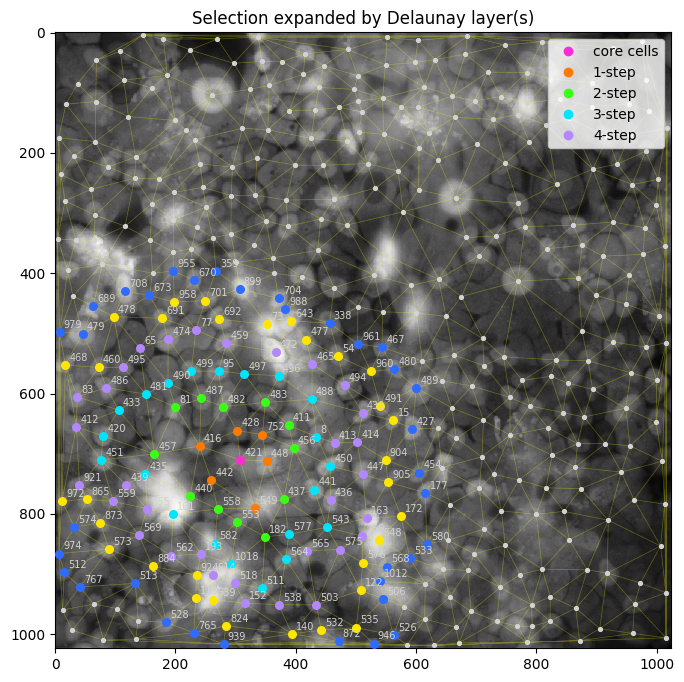

In [62]:
# prepare picked_neighbors for display with plot_layers function
picked_neighbors_layers = picked_neighbors.rename_axis('vertex_id').reset_index()
picked_neighbors_layers = picked_neighbors_layers[["vertex_id", "layer", "x", "y", "track_id"]]

fig, ax = plot_layers(tri_points, tri, picked_neighbors_layers, image=np_erk_show)
plt.show()

# Run it all as one function

In [63]:
def dijkstra_per_frame(arcos_frame, picked_track, picked_cl_id, n_layers, max_dist=150, ce_only=False, discard_nonbin=True):
    assert arcos_frame['t'].nunique() == 1, "pass exactly one frame at a time"
    arcos_frame = arcos_frame.reset_index(drop=True)      # new col: build vertex_id in order of original index. approx sorted according to time and track_id already
    arcos_frame['vertex_id'] = arcos_frame.index

    # convert track ids to vertex ids
    picked_v = arcos_frame.loc[arcos_frame['track_id'].isin(picked_track), 'vertex_id'].to_numpy()

    # point out the CE points which arent present in this frame
    missing = sorted(set(picked_track) - set(arcos_frame['track_id']))

    print(f"picked track IDs: {picked_track}")
    print(f"these correspond to vertex IDs: {picked_v}")
    if missing:
        print(f"not present in this frame: {missing}")

    pts = arcos_frame[['x', 'y']].to_numpy()

    # make delaunay object for all points in frame (takes the longest)
    tri = Delaunay(pts)
    indptr, indices = tri.vertex_neighbor_vertices

    # make csr object to pass to dijkstra
    adj = csr_matrix((np.ones(len(indices)), indices, indptr), shape=(len(pts),) * 2).tocoo() # .tocoo to calculate length easily

    # remove edges that are giga long
    length = np.hypot(*(pts[adj.row] - pts[adj.col]).T)
    keep = length <= max_dist

    if ce_only == True:
        # also remove edges that leave the CE (picked cells always count as inside)
        in_cl = (arcos_frame['cl_id'] == picked_cl_id).fillna(False).to_numpy(dtype=bool)
        # bruh bugfix always include the picked_v in the dijkstra, remove later
        in_cl[picked_v] = True
        keep &= in_cl[adj.row] & in_cl[adj.col]

    adj = csr_matrix((np.ones(keep.sum()), (adj.row[keep], adj.col[keep])), shape=adj.shape)

    # run dijkstra
    hops = dijkstra(adj, unweighted=True, indices=picked_v, min_only=True, limit=n_layers)

    # clean df for output
    keep = np.isfinite(hops) # remove inf vertices (too far to reach)
    tri_df = arcos_frame.loc[keep,:].copy()
    tri_df['layer'] = hops[keep].astype(int) # convert layers to int assuming we keep unweighted dijkstra

    # drop any NaN CE points such as those added for dijkstra
    if discard_nonbin == True:
        tri_df = tri_df.dropna(subset=['cl_id'])

    if len(tri_df) == 0:        # track missing
        return None, tri
    
    return tri_df, tri

,t,obj_id,x,y,intensity_mean_nuc,intensity_mean_cyto,track_id,cnr,rt,cnr.resc,cnr.bin,cl_id
29,29,129,917.671674,684.291845,3952.431330,3142.358491,2,0.795044,2.416667,0.000000,0,NaN
557,29,128,431.960954,669.837310,10699.963124,8685.912596,8,0.811770,2.416667,0.000000,0,NaN
613,29,178,560.822109,644.526048,10298.776366,7618.938511,15,0.739791,2.416667,0.104173,0,NaN
916,29,375,868.744952,677.599362,5715.056323,3663.410714,46,0.641010,2.416667,0.000000,0,NaN
1444,29,313,817.206381,701.537388,7308.747757,7246.678776,48,0.991508,2.416667,0.600651,1,10.0
...,...,...,...,...,...,...,...,...,...,...,...,...
141568,29,385,382.163366,8.527228,9917.517327,7408.340000,1034,0.746995,2.416667,0.000000,0,NaN
141651,29,421,1011.618132,50.565934,5429.508242,4983.653199,1038,0.917883,2.416667,0.000000,0,NaN
141739,29,414,169.005479,651.728767,7292.564384,7169.496222,1046,0.983124,2.416667,0.000000,0,NaN
142238,29,440,916.053398,392.500000,9678.509709,10093.200637,1053,1.042847,2.416667,0.000000,0,NaN


picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [ 89 176 184]


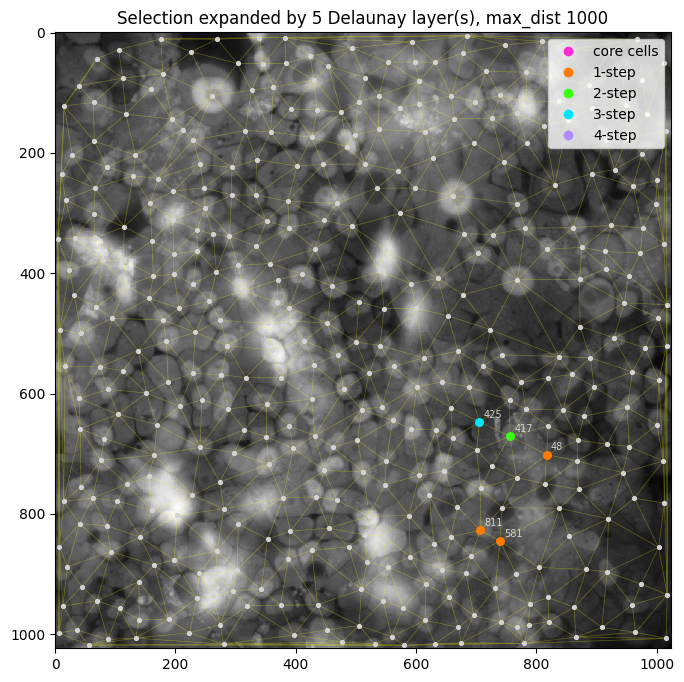

In [64]:
n_frame_show = 29
n_layers = 5
max_dist = 1000
picked_track = [561, 443, 546]

# test_df_arcos = df_ce_filt[df_ce_filt['t'] == n_frame_show]

test_df_arcos = df_arcos_data[df_arcos_data['t'] == n_frame_show]

display(test_df_arcos)

test_tri_df, test_tri = dijkstra_per_frame(test_df_arcos, picked_track=picked_track, picked_cl_id=10, n_layers=n_layers, max_dist=max_dist, ce_only=True)

fig, ax = plot_layers(test_tri.points, test_tri, test_tri_df, image=np_erk_show, labels="track_id")
ax.set_title(f"Selection expanded by {n_layers} Delaunay layer(s), max_dist {max_dist}")
plt.show()

# Watch neighbors over time (also overlay nuclear masks)

picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [107 202 213]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [102 195 205]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [ 99 188 198]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [ 97 185 195]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [ 94 183 193]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [ 95 183 193]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [ 94 182 192]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [ 92 179 189]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [ 92 179 189]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [ 90 177 186]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [ 90 176 184]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [ 90 176 184]
picked track IDs: [561, 443, 546]
these 

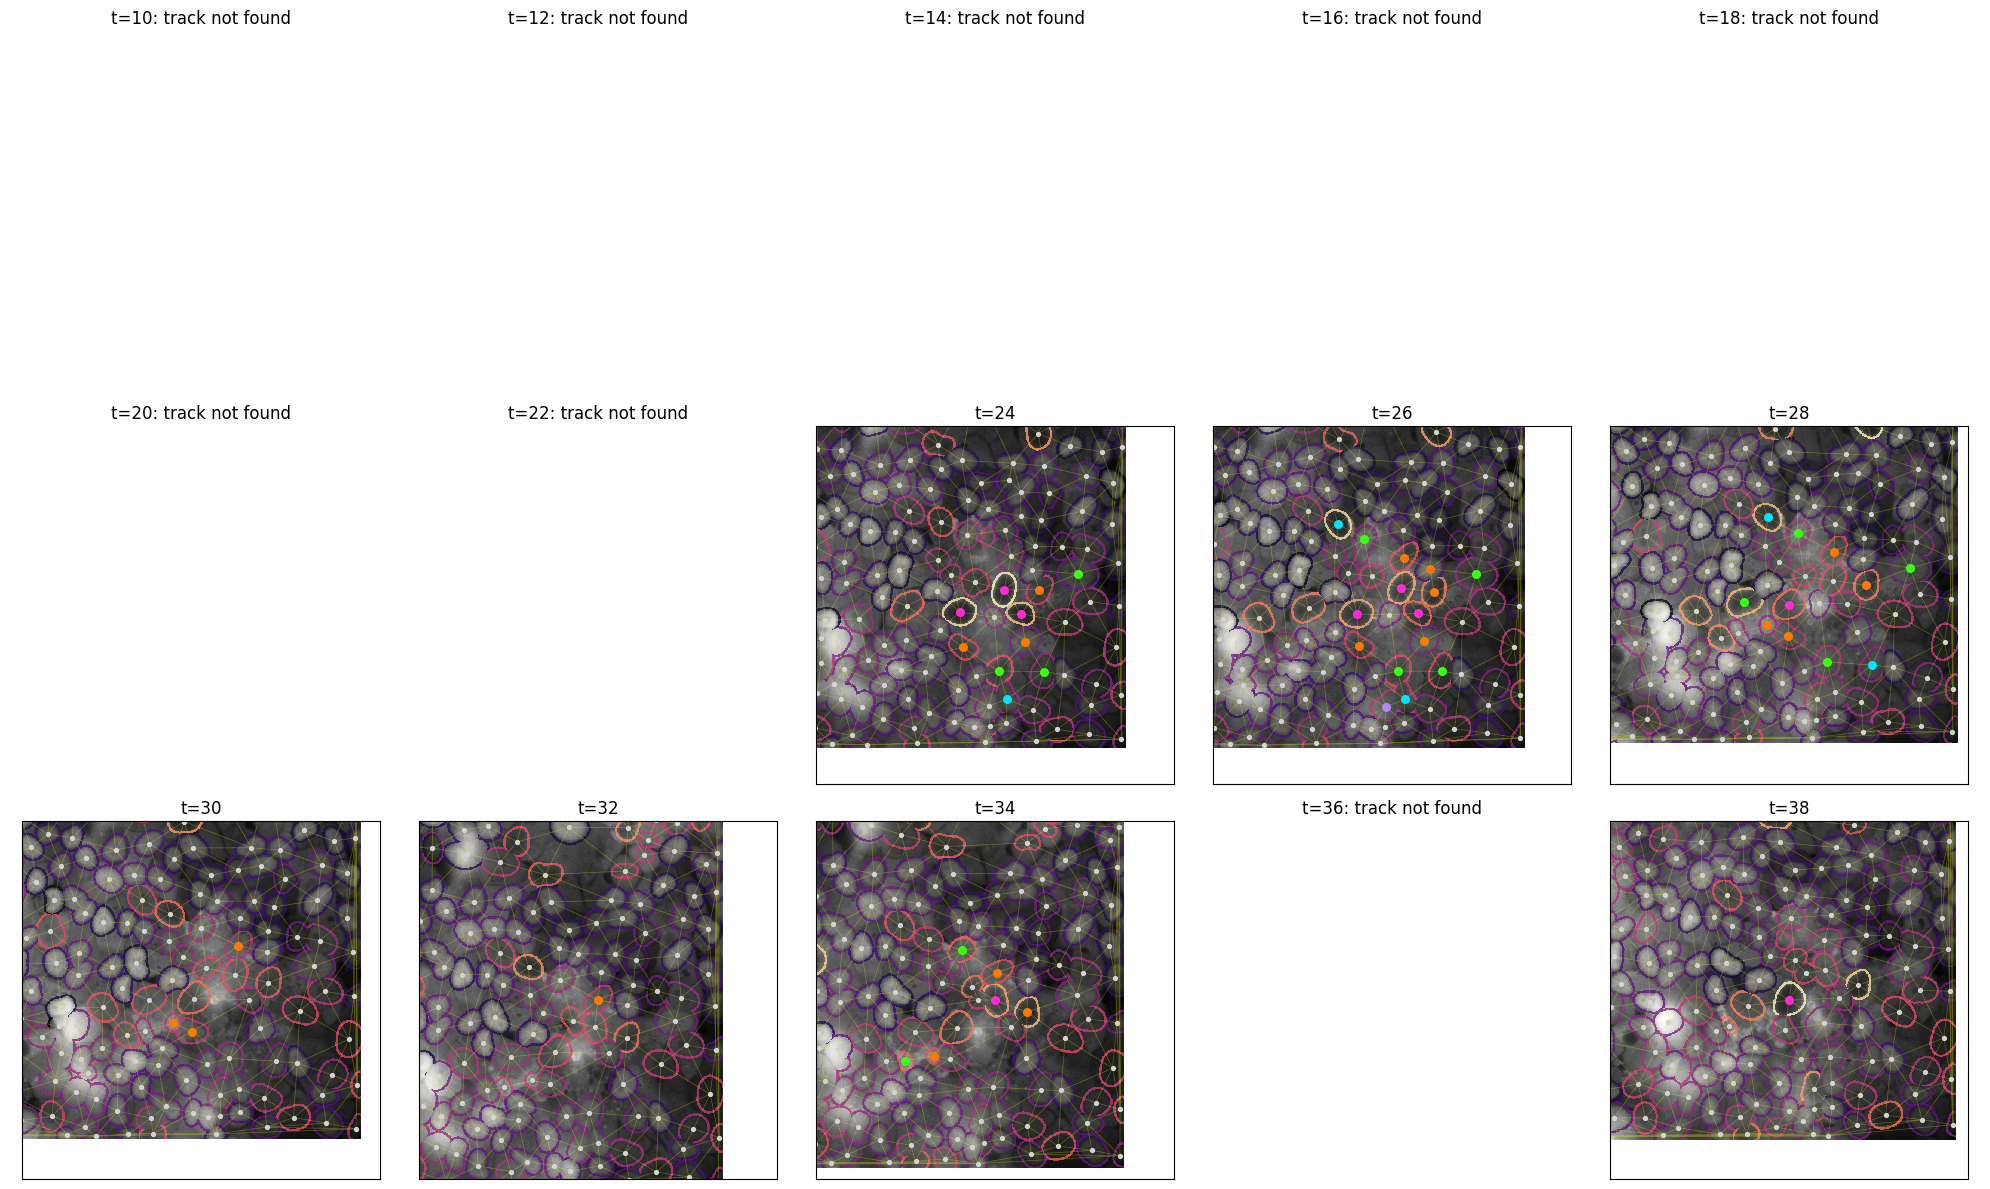

In [65]:
frames = range(10, 40, 2)
ncols = 5
nrows = int(np.ceil(len(frames) / ncols))
# pixels around the picked cell; set to None for full frame
zoom = 300
ce_only = True

fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 4 * nrows), squeeze=False)

for ax, n_frame in zip(axes.ravel(), frames):
    frame = df_arcos_data[df_arcos_data['t'] == n_frame]
    tri_df, tri = dijkstra_per_frame(frame, picked_track=picked_track, picked_cl_id = 10, n_layers=n_layers, max_dist=max_dist, ce_only=ce_only)

    if tri_df is None:                          # track not in this frame
        ax.set_title(f"t={n_frame}: track not found")
        ax.axis('off')
        continue

    kw = {}
    if zoom:
        ref = tri_df[tri_df['layer'] == 0]
        if ref.empty:                           # no picked cell in this frame: centre on whatever is selected
            ref = tri_df
        cx, cy = ref[['x', 'y']].mean()
        kw = dict(xlim=(cx - zoom, cx + zoom), ylim=(cy + zoom, cy - zoom))   # y reversed for imshow

    if ce_only == False:
        pic_tri_df = tri_df[tri_df['cnr.bin'] == 1]
    else:
        pic_tri_df = tri_df

    plot_layers(tri.points, tri, pic_tri_df, image=np_erk[n_frame], labels=None,
                ax=ax, legend=False, title=f"t={n_frame}", **kw)
    ax.set_xticks([]); ax.set_yticks([])

    # add cnr rings
    lab = np_lab_ring_meas[n_frame]
    np_lab_show = np.where(lab == 0, np.nan, lab)      # background -> nan so it stays transparent
    ax.imshow(np_lab_show, cmap="magma", alpha=0.8, interpolation="none")

for ax in axes.ravel()[len(frames):]:        # hide unused panels
    ax.axis('off')

plt.tight_layout()
plt.show()

# Now try on actual binarized CEs

picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [ 92 179 189]


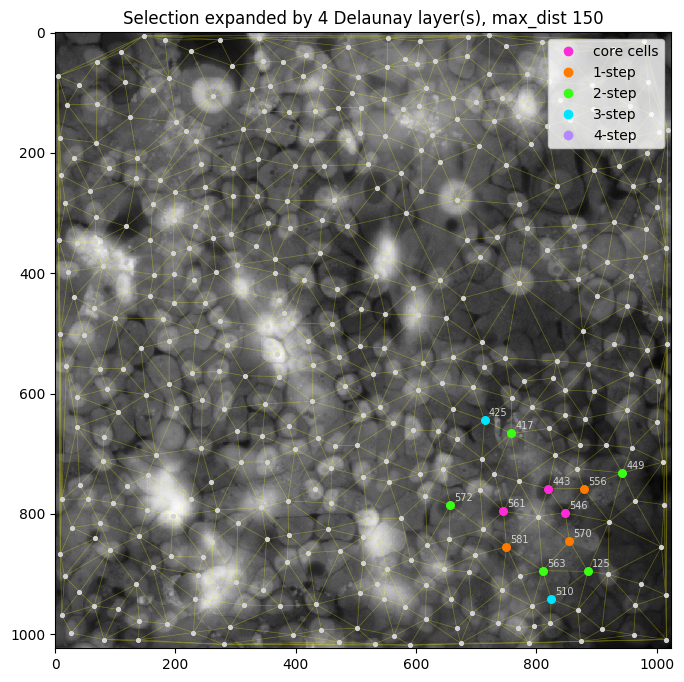

,t,obj_id,x,y,intensity_mean_nuc,intensity_mean_cyto,track_id,cnr,rt,cnr.resc,cnr.bin,cl_id,vertex_id,layer
16,24,95,885.558301,895.698842,5686.922008,5233.522772,125,0.920273,2.0,0.496922,1,10.0,16,2
69,24,8,757.718812,666.397030,8443.367327,7945.320721,417,0.941013,2.0,0.579464,1,10.0,69,2
75,24,175,713.988018,644.554839,5359.541935,5984.085664,425,1.116529,2.0,0.564141,1,10.0,75,3
92,24,128,819.512315,758.406404,5800.326765,8550.483498,443,1.474138,2.0,1.000000,1,10.0,92,0
97,24,53,942.784359,731.759371,6195.050902,5027.902400,449,0.811600,2.0,0.526157,1,10.0,97,2
150,24,170,824.316534,941.707339,6591.673740,6148.341463,510,0.932744,2.0,0.469943,1,10.0,150,3
179,24,242,847.885151,798.220418,4835.082367,6618.315589,546,1.368811,2.0,1.000000,1,10.0,179,0
185,24,160,878.709378,758.129991,6048.696379,6372.026316,556,1.053454,2.0,0.512761,1,10.0,185,1
189,24,82,745.195051,795.826783,5305.534207,7618.011589,561,1.435861,2.0,1.000000,1,10.0,189,0
191,24,19,810.221078,894.454041,6584.445325,7378.957356,563,1.120665,2.0,1.000000,1,10.0,191,2


In [66]:
picked_ce = 10
n_frame_show = 24

n_layers = 4
max_dist = 150

df_arcos_frame = df_arcos_data[df_arcos_data['t'] == n_frame_show]

picked_track = [561, 443, 546]

test_tri_df, test_tri = dijkstra_per_frame(df_arcos_frame, picked_track=picked_track, n_layers=n_layers, max_dist=max_dist, picked_cl_id=picked_ce)

fig, ax = plot_layers(test_tri.points, test_tri, test_tri_df, image=np_erk_show, labels="track_id")
ax.set_title(f"Selection expanded by {n_layers} Delaunay layer(s), max_dist {max_dist}")
plt.show()
display(test_tri_df)

In [ ]:
frames = range(5, 51)

picked_track = [561, 443, 546]
picked_ce = 10
ce_only = True
discard_nonbin = False
n_layers = 6

# one colour range for ALL frames, computed once before the loop
sl = slice(frames.start, frames.stop)
erk_min, erk_max = np.nanmin(np_erk[sl]), np.nanmax(np_erk[sl])
ring_vals = np_lab_ring_meas[sl]
ring_vals = ring_vals[ring_vals != 0]                  # 0 = background
ring_min, ring_max = np.nanmin(ring_vals), np.nanmax(ring_vals)

rgb_frames = []

for n_frame in frames:
    fig, ax = plt.subplots(figsize=(6, 6))   # one figure per frame (replaces the montage grid)
    frame = df_arcos_data[df_arcos_data['t'] == n_frame]
    tri_df, tri = dijkstra_per_frame(frame, picked_track=picked_track, picked_cl_id=picked_ce, n_layers=n_layers, max_dist=max_dist, ce_only=ce_only, discard_nonbin=discard_nonbin)


    pic_tri_df = None                                   # reset every frame, so a stale table is never reused

    if tri_df is not None:
        is_picked = tri_df['track_id'].isin(picked_track)

        # dijkstra_per_frame() will return cl_id NaN if you choose discard_nonbin=False (the core cells which are not signaling at the time) so we mark them with -1 and plot_layers() will later mark them with a pink ring
        tri_df = tri_df.copy()
        tri_df.loc[is_picked & tri_df['cl_id'].isna(), 'cl_id'] = -1

        # ce_only: keep everything as is
        if ce_only == True:
            pic_tri_df = tri_df.copy()
        # not ce_only: default to plotting all binarized cells in range along with picked ids
        elif ce_only == False: 
            pic_tri_df = tri_df[(tri_df['cnr.bin'] == 1) | is_picked].copy()

    # ok make the plot
    note = f", n={0 if pic_tri_df is None else sum(pic_tri_df['cl_id'] != -1)}"
    plot_layers(tri.points, tri, pic_tri_df, image=np_erk[n_frame],
                ax=ax, legend=True, title=f"t={n_frame}{note}",
                vmin=erk_min, vmax=erk_max, legend_max=6)                       # same grey scale every frame
    
    ax.set_xticks([]); ax.set_yticks([])

    # add cnr rings
    lab = np_lab_ring_meas[n_frame]
    np_lab_show = np.where(lab == 0, np.nan, lab)      # background -> nan so it stays transparent
    ax.imshow(np_lab_show, cmap="magma", alpha=0.8, interpolation="none",
              vmin=ring_min, vmax=ring_max)                       # same ring scale every frame

    ax.set_xlim(600, 1000)
    ax.set_ylim(1000, 600)

    # grab the finished figure as an image, then close it
    fig.canvas.draw()
    rgb = np.asarray(fig.canvas.buffer_rgba())[..., :3]
    rgb_frames.append(rgb.copy())            # replaces the gif_frames.append(...quantize...) line
    plt.close(fig)

reserved = color_palette + ["#D3D3D3", "#000000", "#FFFFFF"]               # plus light-grey cell dots, black outline, white
reserved_rgb = [tuple(int(c[i:i+2], 16) for i in (1, 3, 5)) for c in reserved]
K = len(reserved_rgb)

pal = Image.fromarray(np.vstack(rgb_frames)).quantize(colors=256 - K)     # palette for everything else
flat = (pal.getpalette() + [0] * 768)[: 3 * (256 - K)]
flat += [v for rgb in reserved_rgb for v in rgb]                          # the exact colors go in the last slots
pal_img = Image.new("P", (1, 1))
pal_img.putpalette(flat)

gif_frames = [Image.fromarray(r).quantize(palette=pal_img, dither=0) for r in rgb_frames]


gif_frames[0].save("ce_10-small3.gif", save_all=True, append_images=gif_frames[1:], duration=150, loop=0)

picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [108 203 214]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [108 203 214]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [107 202 213]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [107 202 213]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [107 202 213]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [107 202 213]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [103 197 207]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [102 195 205]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [102 194 204]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [ 99 188 198]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [ 99 188 198]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [ 97 185 195]
picked track IDs: [561, 443, 546]
these 

In [100]:
def ce_dijkstra(df_arcos_data, frames, picked_track, picked_ce, n_layers=4, max_dist=150, ce_only=True, discard_nonbin=False):
    layer_rows = []

    for n_frame in frames:
        frame = df_arcos_data[df_arcos_data['t'] == n_frame]
        tri_df, tri = dijkstra_per_frame(frame, picked_track=picked_track, picked_cl_id=picked_ce, n_layers=n_layers, max_dist=max_dist, ce_only=ce_only, discard_nonbin=discard_nonbin)

        if tri_df is not None:
            layer_rows.append(tri_df[['t', 'track_id', 'layer']])

    all_layers = pd.concat(layer_rows, ignore_index=True)

    df_dijkstra = (df_arcos_data.drop(columns='layer', errors='ignore')          # so re-running the cell doesn't create layer_x / layer_y
            .merge(all_layers, on=['t', 'track_id'], how='left', validate='m:1'))
    df_dijkstra.index = df_arcos_data.index                                      # merge resets the index; this puts the original one back
    df_dijkstra['layer'] = df_dijkstra['layer'].astype('Int64')                       # whole numbers, <NA> where a cell wasn't selected

    return df_dijkstra

frames = range(0, 500)

picked_track = [561, 443, 546]
picked_ce = 10
ce_only = True

df_dijkstra = ce_dijkstra(df_arcos_data, frames=frames, picked_track=picked_track, picked_ce=picked_ce, ce_only=True)
# 3.3s

picked track IDs: [561, 443, 546]
these correspond to vertex IDs: []
not present in this frame: [443, 546, 561]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [107 202 213]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [107 202 213]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [107 202 213]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [107 202 213]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [108 203 214]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [108 203 214]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [107 202 213]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [107 202 213]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [107 202 213]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [107 202 213]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [103 197 207]
picked t

In [101]:
display(df_arcos_data[df_arcos_data['track_id'].isin(picked_track)])

display(df_dijkstra[df_dijkstra['track_id'].isin(picked_track)])

display(df_dijkstra.dropna())

,t,obj_id,x,y,intensity_mean_nuc,intensity_mean_cyto,track_id,cnr,rt,cnr.resc,cnr.bin,cl_id
32994,1,49,812.070132,756.912541,7639.183993,7491.344178,443,0.980647,0.083333,0.000000,0,NaN
32995,2,71,813.641955,754.814659,7681.976411,7468.642123,443,0.972229,0.166667,0.000000,0,NaN
32996,3,13,814.556557,754.286885,7617.846721,7433.217538,443,0.975764,0.250000,0.000000,0,NaN
32997,4,13,814.639439,750.871287,7598.018152,7312.693220,443,0.962447,0.333333,0.000000,0,NaN
32998,5,29,815.814602,750.316653,7555.197703,7352.654762,443,0.973192,0.416667,0.000000,0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
72772,523,100,723.879363,731.751990,7998.995101,7198.483264,561,0.899923,43.583333,0.000384,0,NaN
72773,524,84,724.328667,731.494218,8057.449178,7214.963203,561,0.895440,43.666667,0.000000,0,NaN
72774,525,118,722.855327,731.501816,8045.651937,7030.315217,561,0.873803,43.750000,0.000000,0,NaN
72775,526,108,724.757875,731.669549,8156.880173,7218.303347,561,0.884934,43.833333,0.000000,0,NaN


,t,obj_id,x,y,intensity_mean_nuc,intensity_mean_cyto,track_id,cnr,rt,cnr.resc,cnr.bin,cl_id,layer
32994,1,49,812.070132,756.912541,7639.183993,7491.344178,443,0.980647,0.083333,0.000000,0,NaN,0
32995,2,71,813.641955,754.814659,7681.976411,7468.642123,443,0.972229,0.166667,0.000000,0,NaN,0
32996,3,13,814.556557,754.286885,7617.846721,7433.217538,443,0.975764,0.250000,0.000000,0,NaN,0
32997,4,13,814.639439,750.871287,7598.018152,7312.693220,443,0.962447,0.333333,0.000000,0,NaN,0
32998,5,29,815.814602,750.316653,7555.197703,7352.654762,443,0.973192,0.416667,0.000000,0,NaN,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
72772,523,100,723.879363,731.751990,7998.995101,7198.483264,561,0.899923,43.583333,0.000384,0,NaN,<NA>
72773,524,84,724.328667,731.494218,8057.449178,7214.963203,561,0.895440,43.666667,0.000000,0,NaN,<NA>
72774,525,118,722.855327,731.501816,8045.651937,7030.315217,561,0.873803,43.750000,0.000000,0,NaN,<NA>
72775,526,108,724.757875,731.669549,8156.880173,7218.303347,561,0.884934,43.833333,0.000000,0,NaN,<NA>


,t,obj_id,x,y,intensity_mean_nuc,intensity_mean_cyto,track_id,cnr,rt,cnr.resc,cnr.bin,cl_id,layer
1440,25,324,826.125243,702.605825,6598.585437,7383.637736,48,1.118973,2.083333,0.941386,1,10.0,1
1441,26,334,820.864008,703.821063,6669.392638,7638.458929,48,1.145301,2.166667,1.000000,1,10.0,1
1442,27,349,819.297917,704.919792,6868.078125,7835.789668,48,1.140900,2.250000,1.000000,1,10.0,1
1443,28,355,816.076023,703.089669,7121.545809,7668.973333,48,1.076869,2.333333,0.828836,1,10.0,1
1444,29,313,817.206381,701.537388,7308.747757,7246.678776,48,0.991508,2.416667,0.600651,1,10.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
122655,29,229,706.843137,827.380952,11035.014006,10446.584375,811,0.946676,2.416667,0.645525,1,10.0,1
122656,30,260,709.600583,828.973761,10621.938776,10153.746711,811,0.955922,2.500000,0.659207,1,10.0,1
122657,31,334,708.965779,830.673004,10426.859316,10244.428571,811,0.982504,2.583333,0.777466,1,10.0,1
122659,33,238,702.880383,834.727273,10021.105263,10470.734783,811,1.044868,2.750000,1.000000,1,10.0,1


In [102]:
df_dijkstra = df_dijkstra.dropna()

df_dijkstra = df_dijkstra.rename(columns={
    "t": "axis-0",
    "y": "axis-1",
    "x": "axis-2",
})

df_dijkstra = df_dijkstra[['axis-0', 'axis-1', 'axis-2', 'cl_id', 'layer']].copy()

display(df_dijkstra)

,axis-0,axis-1,axis-2,cl_id,layer
1440,25,702.605825,826.125243,10.0,1
1441,26,703.821063,820.864008,10.0,1
1442,27,704.919792,819.297917,10.0,1
1443,28,703.089669,816.076023,10.0,1
1444,29,701.537388,817.206381,10.0,1
...,...,...,...,...,...
122655,29,827.380952,706.843137,10.0,1
122656,30,828.973761,709.600583,10.0,1
122657,31,830.673004,708.965779,10.0,1
122659,33,834.727273,702.880383,10.0,1


In [103]:
# using CE saving script from ARCOS

COL_COLL_ID = 'layer'
COL_FRAME = 't'
COL_POS = ('x','y')

df_out = df_dijkstra

# CE points
codes = pd.factorize(df_out[COL_COLL_ID], sort=True)[0]
df_w_colors = df_out.copy()
df_w_colors["colors"] = np.array(color_palette)[1 + codes % (len(color_palette) - 1)]

coord_cols = ["axis-0", "axis-1", "axis-2"]   # frame, y, x
out = df_w_colors.rename(columns={
    COL_FRAME: "axis-0",
    COL_POS[1]: "axis-1",
    COL_POS[0]: "axis-2",
})

# hex -> separate r, g, b columns (a tuple in a CSV cell is read back as text)
from matplotlib.colors import to_rgb
out[["r", "g", "b"]] = [to_rgb(c) for c in out["colors"]]

out = out[coord_cols + ["r", "g", "b", COL_COLL_ID]]
out.to_csv(f"dijkstra_points.csv", index=False)
print("Saved dijkstra_points.csv!")

Saved dijkstra_points.csv!


In [ ]:
frames = range(0, 500)
picked_ce_list = range(1, 10)

results = {}
for ce in picked_ce_list:
    ce_points = df_arcos_data[df_arcos_data['cl_id'] == ce]
    if ce_points.empty:                                   # CE has no points: skip
        continue

    first_t = ce_points['t'].min()                        # first frame of this CE
    picked_track = ce_points.loc[ce_points['t'] == first_t, 'track_id'].unique().tolist()

    results[ce] = ce_dijkstra(
        df_arcos_data, frames=frames, picked_track=picked_track,
        picked_ce=ce, ce_only=True,
    )

df_dijkstra = pd.concat(
    [df.assign(picked_ce=ce) for ce, df in results.items()],
    ignore_index=True,
) if results else None

# 18.5s

picked track IDs: [596, 635, 663]
these correspond to vertex IDs: []
not present in this frame: [596, 635, 663]
picked track IDs: [596, 635, 663]
these correspond to vertex IDs: [245 279 300]
picked track IDs: [596, 635, 663]
these correspond to vertex IDs: [245 279 300]
picked track IDs: [596, 635, 663]
these correspond to vertex IDs: [245 279 300]
picked track IDs: [596, 635, 663]
these correspond to vertex IDs: [245 279 300]
picked track IDs: [596, 635, 663]
these correspond to vertex IDs: [246 280 301]
picked track IDs: [596, 635, 663]
these correspond to vertex IDs: [245 279 300]
picked track IDs: [596, 635, 663]
these correspond to vertex IDs: [245 279 300]
picked track IDs: [596, 635, 663]
these correspond to vertex IDs: [245 279 300]
picked track IDs: [596, 635, 663]
these correspond to vertex IDs: [245 279 300]
picked track IDs: [596, 635, 663]
these correspond to vertex IDs: [245 279 300]
picked track IDs: [596, 635, 663]
these correspond to vertex IDs: [239 273 294]
picked t

In [95]:
df_dijkstra.dropna()

,t,obj_id,x,y,intensity_mean_nuc,intensity_mean_cyto,track_id,cnr,rt,cnr.resc,cnr.bin,cl_id,layer,picked_ce
82570,3,247,846.415789,117.750000,11403.405263,11470.939633,596,1.005922,0.250000,0.615511,1,3.0,0,3
82571,4,376,846.592384,116.146685,10433.686883,11168.853535,596,1.070461,0.333333,0.621352,1,3.0,0,3
82620,55,320,824.078070,82.186842,9398.674561,8652.837429,596,0.920644,4.583333,0.465253,1,18.0,0,3
82621,56,264,823.691244,80.667281,9631.120737,8094.235772,596,0.840425,4.666667,0.543585,1,18.0,0,3
82622,57,281,821.414456,81.038426,10184.687100,8723.651625,596,0.856546,4.750000,0.470411,1,18.0,0,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1131725,24,40,979.870910,372.315883,8090.779298,8480.724390,665,1.048196,2.000000,0.437447,1,9.0,0,9
1133114,23,433,913.283525,389.758621,8134.691571,8378.606987,672,1.029985,1.916667,0.818781,1,9.0,0,9
1133115,24,437,918.070934,380.584775,8699.641869,8794.231111,672,1.010873,2.000000,0.854908,1,9.0,0,9
1138680,23,204,900.420553,438.696891,6630.732297,7861.665000,699,1.185641,1.916667,0.825987,1,9.0,0,9
